# Tutorial: CommonRoad Route Planner

This tutorial demonstrates how the CommonRoad Route Planner package can be used to plan high-level routes for planning problems given in CommonRoad scenarios.

## 0. Preparation
* you have gone through the tutorial for **CommonRoad Input-Output**
* you have installed the [route planner](https://gitlab.lrz.de/tum-cps/commonroad-route-planner) package

Let's start with importing relevant modules and classes.

In [9]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np # Make sure numpy is imported

# add the root folder to python path
path_notebook = os.getcwd()
sys.path.append(os.path.join(path_notebook, "../"))

import matplotlib.pyplot as plt
from commonroad.common.file_reader import CommonRoadFileReader
# Remove RoutePlanner import if no longer needed, or keep if used elsewhere
# from commonroad_route_planner.route_planner import RoutePlanner
from commonroad_route_planner.utility.visualization import visualize_route
from commonroad.visualization.mp_renderer import MPRenderer

# Import the Fast API module
import commonroad_route_planner.fast_api.fast_api as cr_rp_api

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Loading CR Scenario and Planning Problem
In the next step, we load a CommonRoad scenario and its planning problem(s), for which the routes should be planned. The route planner handles **one planning problem** at a time, thus we need to manually specify the planning problem for which the routes should be planned. In our case, we select the first planning problem in the planning problem set. The meaning of the symbols in a scenario are explained as follows:
* **Dot**: initial state of the planning problem projected onto the position domain
* **Blue rectangle**: dynamic obstacle
* **Yellow rectangle**: goal region projected onto the position domain

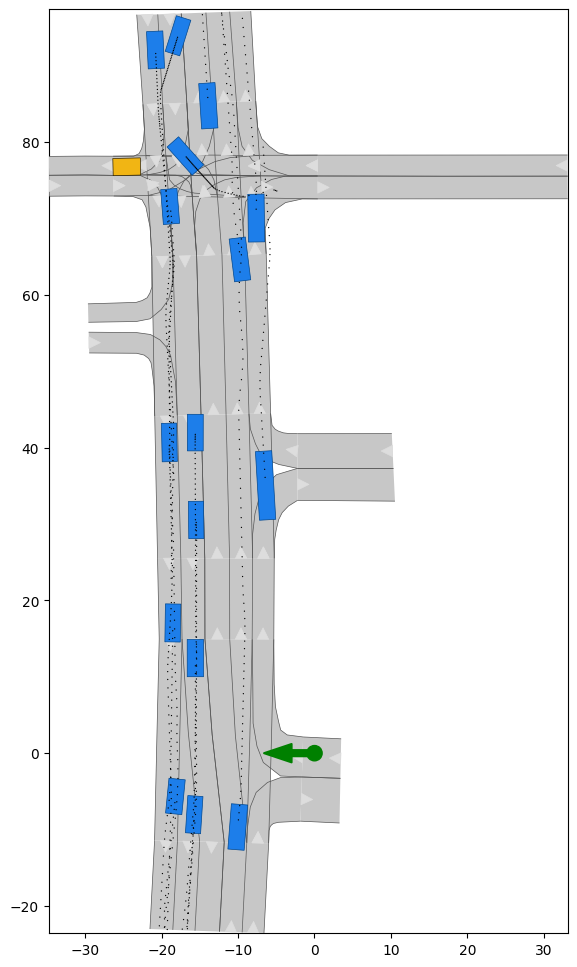

In [10]:
# load scenario
path_scenario = os.path.join(path_notebook, "../../scenarios/tutorial/")
id_scenario = 'USA_Peach-2_1_T-1'

# read in scenario and planning problem set
scenario, planning_problem_set = CommonRoadFileReader(path_scenario + id_scenario + '.xml').open()
# retrieve the first planning problem in the problem set
planning_problem = list(planning_problem_set.planning_problem_dict.values())[0]

# plot the scenario and the planning problem set
renderer = MPRenderer(figsize=(12, 12))

scenario.draw(renderer)
planning_problem.draw(renderer)

renderer.render()
plt.margins(0, 0)

## 2. Generating a Reference Path using the Fast API

Instead of instantiating the full `RoutePlanner`, we can use the `fast_api` module within the `commonroad-route-planner` package to directly generate a smoothed reference path.

### 2.1 Function Call
We call `generate_reference_path_from_lanelet_network_and_planning_problem`, passing the `scenario.lanelet_network` and the specific `planning_problem`. This function handles the route finding and path smoothing internally.

### 2.2 Retrieving Reference Path Coordinates
The function returns an object (`reference_path_object` in the code) which typically contains the smoothed reference path coordinates. These coordinates can usually be accessed via the `.reference_path` attribute of the returned object (e.g., `reference_path_object.reference_path`). The path is a smoothed polyline.

In [11]:
# Generate the reference path using the Fast API function
try:
    reference_path_object = cr_rp_api.generate_reference_path_from_lanelet_network_and_planning_problem(
               lanelet_network=scenario.lanelet_network,
               planning_problem=planning_problem
     ) 
    print("Reference path generated successfully using Fast API.")
except Exception as e:
    print(f"Error generating reference path using Fast API: {e}")
    reference_path_object = None

# Initialize coordinates
reference_path_coords = None

# Check if the path object was generated
if reference_path_object is None:
    print("\nNo reference path could be generated!")
else:
    # Retrieve the reference path coordinates using the .reference_path attribute
    # Assuming the returned object has this attribute holding the smoothed path
    try:
        reference_path_coords = reference_path_object.reference_path # Accessing the coordinates
        print("\nCoordinates [x, y] (Smoothed Reference Path from reference_path_object.reference_path):")
        # Print only the first few and last few coordinates for brevity if it's long
        if reference_path_coords is not None and len(reference_path_coords) > 10:
             print(np.vstack((reference_path_coords[:5], [["...", "..."]], reference_path_coords[-5:])))
        else:
             print(reference_path_coords)
    except AttributeError:
        print("\nWarning: Could not retrieve .reference_path attribute from the generated reference_path_object.")
        # Fallback: Maybe the object itself is the path? Check if it's iterable.
        try:
            # Check if it looks like a list/array of coordinates
            if hasattr(reference_path_object, '__iter__') and len(reference_path_object) > 0 and hasattr(reference_path_object[0], '__iter__') and len(reference_path_object[0]) == 2:
                 reference_path_coords = np.array(reference_path_object)
                 print("\nCoordinates [x, y] (Assuming returned object is the path itself):")
                 if len(reference_path_coords) > 10:
                      print(np.vstack((reference_path_coords[:5], [["...", "..."]], reference_path_coords[-5:])))
                 else:
                      print(reference_path_coords)
            else:
                 print("Returned object structure not recognized for coordinate extraction.")
        except Exception as fallback_e:
             print(f"Could not extract coordinates via fallback: {fallback_e}")

    except Exception as e:
        print(f"\nAn error occurred retrieving reference path coordinates: {e}")

Reference path generated successfully using Fast API.

Coordinates [x, y] (Smoothed Reference Path from reference_path_object.reference_path):
[['3.438' '-0.70515']
 ['3.4301943269998336' '-0.7048234647576808']
 ['3.414582980999502' '-0.7041703942730423']
 ['3.391165961999003' '-0.7031907885460845']
 ['3.3599432699983387' '-0.7018846475768075']
 ['...' '...']
 ['-26.29138962011583' '76.88007983107063']
 ['-26.3098937720695' '76.87980789864238']
 ['-26.32377188603475' '76.8796039493212']
 ['-26.333023962011584' '76.87946798310706']
 ['-26.33765' '76.8794']]


## 3. Visualizing planning results

## 3. Visualizing planning results

The reference path generated by the Fast API can be visualized using the `visualize_route` utility function. The code snippet below calls this function, passing the `reference_path_object` returned by the API, along with the `scenario` and `planning_problem`.

The code is currently configured to draw the smoothed reference path (red line) with `draw_reference_path=True` and *not* to draw the route lanelets (no green highlighting) by setting `draw_route_lanelets=False`.

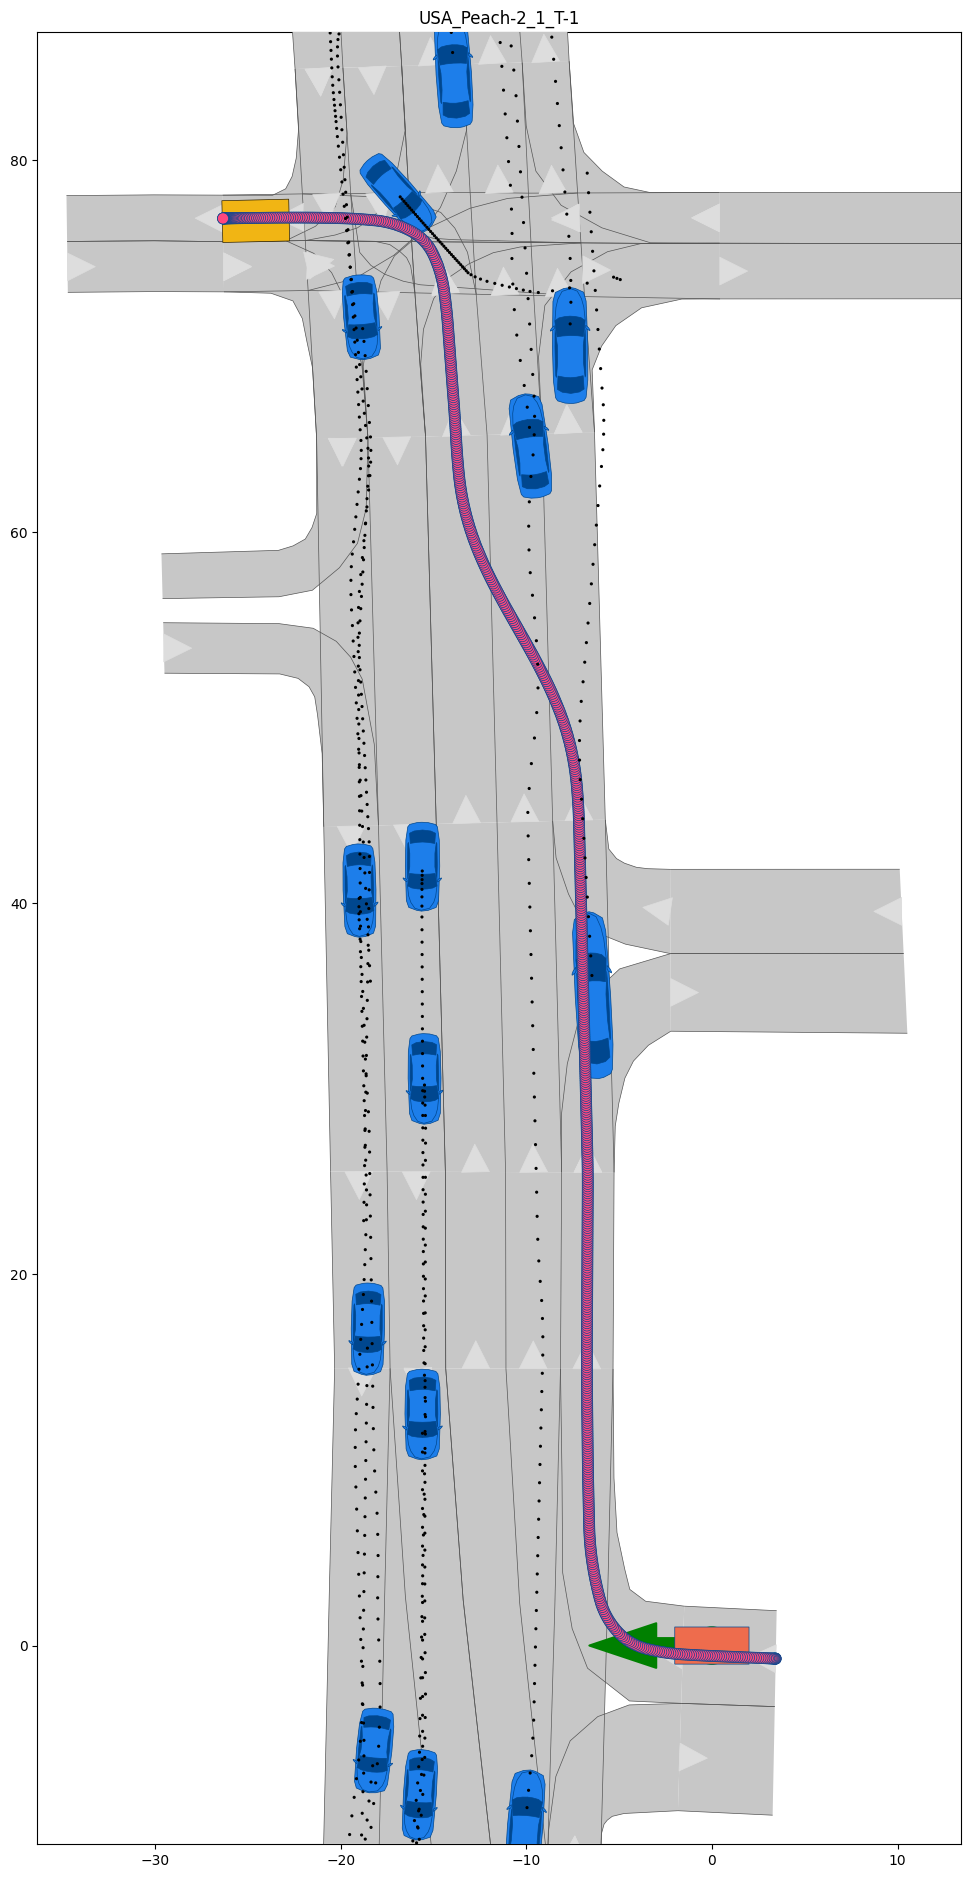

In [12]:
# Check if a reference path object was successfully generated before visualizing
if reference_path_object:
    # Visualize the reference path using the dedicated function
    # This function handles creating and showing the plot
    visualize_route(reference_path_object, # Use the object returned by the Fast API
                    scenario,
                    planning_problem,
                    draw_reference_path=True,  # Set to True as requested
                    draw_route_lanelets=False, # Set to True if you want to see the lanelets
                    size_x=12,
                    save_img=False)
else:
    print("Skipping visualization as no reference path object was generated.")